# Crime category classifier (47 categories) - DeBERTa-v3 fine-tuning on Colab
Runtime > Change runtime type > **T4 GPU** (or better) before running.
Upload `crime_final_train.csv` and `crime_final_test.csv` (columns: text, category) when asked.

In [ ]:
!pip -q install -U transformers datasets accelerate evaluate scikit-learn sentencepiece

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [ ]:
import os, inspect, json, numpy as np, pandas as pd, torch
from google.colab import files

# --- upload the two CSVs (skip if already in /content) ---
for f in ("crime_final_train.csv", "crime_final_test.csv"):
    if not os.path.exists(f):
        print("Upload", f); files.upload()

MODEL_NAME = "microsoft/deberta-v3-base"   # fallback if fp16 NaN / OOM: "roberta-base" or "distilroberta-base"
MAX_LEN    = 128
EPOCHS     = 3
LR         = 3e-5
BATCH      = 16          # per-device; effective batch = BATCH * GRAD_ACC
GRAD_ACC   = 2
SEED       = 42

tr = pd.read_csv("crime_final_train.csv").dropna(subset=["text", "category"])
te = pd.read_csv("crime_final_test.csv").dropna(subset=["text", "category"])
tr["text"] = tr.text.astype(str); te["text"] = te.text.astype(str)
labels = sorted(tr.category.unique()); l2i = {l: i for i, l in enumerate(labels)}; i2l = {i: l for l, i in l2i.items()}
print(len(tr), len(te), len(labels), "classes")

# stratified validation split from train (8%)
from sklearn.model_selection import train_test_split
tr, va = train_test_split(tr, test_size=0.08, stratify=tr.category, random_state=SEED)
print("train", len(tr), "val", len(va), "test", len(te))

78357 14633 47 classes
train 72088 val 6269 test 14633


In [ ]:
# class weights (inverse frequency, softened) so big classes (non_crime, phishing) do not dominate
counts = tr.category.value_counts()
w = np.array([(len(tr) / (len(labels) * counts[l])) ** 0.5 for l in labels], dtype="float32")
class_weights = torch.tensor(w / w.mean())

In [ ]:
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding, EarlyStoppingCallback)

tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def to_ds(df):
    ds = Dataset.from_dict({"text": df.text.tolist(), "label": [l2i[c] for c in df.category]})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN), batched=True, remove_columns=["text"])

ds_tr, ds_va, ds_te = to_ds(tr), to_ds(va), to_ds(te)

def load_model():
    kw = dict(num_labels=len(labels), id2label=i2l, label2id=l2i)
    try:    m = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, dtype=torch.float32, **kw)        # newer transformers
    except TypeError: m = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, torch_dtype=torch.float32, **kw)  # older
    return m.float()          # make sure every weight is fp32; mixed precision (fp16) is applied by the Trainer, not by the weights
model = load_model()
print("weights dtype:", next(model.parameters()).dtype)   # must say torch.float32

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

Map:   0%|          | 0/72088 [00:00<?, ? examples/s]

...

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  371MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
classifier.bias                         | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
pooler.den

weights dtype: torch.float32


In [ ]:
from sklearn.metrics import accuracy_score, f1_score

def metrics(ev):
    p = np.argmax(ev.predictions, axis=1)
    return {"accuracy": accuracy_score(ev.label_ids, p), "macro_f1": f1_score(ev.label_ids, p, average="macro")}

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels_ = inputs.pop("labels")
        out = model(**inputs)
        logits = out.logits.float()                                   # fp32 loss even under fp16 autocast
        loss = torch.nn.functional.cross_entropy(logits, labels_, weight=class_weights.to(logits.device, dtype=torch.float32),
                                                 label_smoothing=0.05)
        return (loss, out) if return_outputs else loss

sig = inspect.signature(TrainingArguments.__init__).parameters
args = dict(
    output_dir="out", num_train_epochs=EPOCHS, learning_rate=LR,
    per_device_train_batch_size=BATCH, per_device_eval_batch_size=64, gradient_accumulation_steps=GRAD_ACC,
    weight_decay=0.01, lr_scheduler_type="linear",
    save_strategy="epoch", save_total_limit=1, load_best_model_at_end=True, metric_for_best_model="macro_f1",
    logging_steps=100, report_to="none", seed=SEED,
    fp16=torch.cuda.is_available(),       # safe now that weights are fp32; if loss becomes nan set False (slower)
)
args["eval_strategy" if "eval_strategy" in sig else "evaluation_strategy"] = "epoch"
steps_total = int(np.ceil(len(tr) / (BATCH * GRAD_ACC)) * EPOCHS)
if "warmup_ratio" in sig: args["warmup_ratio"] = 0.1            # older versions
else:                     args["warmup_steps"] = int(0.1 * steps_total)   # newer versions removed warmup_ratio
args = {k: v for k, v in args.items() if k in sig}            # drop anything this version does not know
targs = TrainingArguments(**args)

tk = {"processing_class": tok} if "processing_class" in inspect.signature(Trainer.__init__).parameters else {"tokenizer": tok}
trainer = WeightedTrainer(model=model, args=targs, train_dataset=ds_tr, eval_dataset=ds_va,
                          data_collator=DataCollatorWithPadding(tok), compute_metrics=metrics,
                          callbacks=[EarlyStoppingCallback(early_stopping_patience=1)], **tk)

model.safetensors: reconstructing file:   0%|          |  0.00B /  371MB            

model.safetensors: downloading bytes:           |  0.00B            

In [ ]:
trainer.train()      # roughly 30-60+ min per epoch on a T4 (not measured). Reduce MAX_LEN or use distilroberta to speed up.

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.871420,0.432959,0.993938,0.995823
2,0.825006,0.423892,0.996491,0.997976
3,0.827623,0.421908,0.996331,0.997633


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=6759, training_loss=1.2758055550227734, metrics={'train_runtime': 1998.8282, 'train_samples_per_second': 108.195, 'train_steps_per_second': 3.381, 'total_flos': 8489224672732608.0, 'train_loss': 1.2758055550227734, 'epoch': 3.0})

In [ ]:
# ---- evaluate on the held-out-scenario test set ----
from sklearn.metrics import classification_report
pred = trainer.predict(ds_te)
logits = pred.predictions; y = pred.label_ids; p = logits.argmax(1)
print("TEST accuracy", accuracy_score(y, p), "macro-F1", f1_score(y, p, average="macro"))
rep = classification_report(y, p, target_names=labels, zero_division=0, output_dict=True)
print(pd.DataFrame(rep).T.round(2).sort_values("f1-score").to_string())   # weakest classes first

# most common confusions
from collections import Counter
conf = Counter((i2l[a], i2l[b]) for a, b in zip(y, p) if a != b)
print("\nTop confusions (true -> predicted):")
for (a, b), n in conf.most_common(15): print(f"{n:4d}  {a} -> {b}")

TEST accuracy 0.789858538918882 macro-F1 0.7714535609841471
                                   precision  recall  f1-score   support
exam_cheating_academic_fraud            0.40    0.01      0.02    228.00
unauthorized_access_hacking             0.20    0.54      0.29    117.00
other_crime                             0.43    0.34      0.38    214.00
cryptocurrency_crime                    1.00    0.30      0.46    208.00
financial_fraud_forgery                 0.45    0.60      0.51    600.00
arson_vandalism                         0.68    0.44      0.53    600.00
assault_battery                         0.37    0.94      0.53    143.00
ransomware_malware                      0.47    0.64      0.54    197.00
hate_crime                              0.69    0.46      0.55    234.00
online_extortion_sextortion             0.66    0.56      0.61    195.00
extortion_blackmail                     0.78    0.51      0.62    247.00
embezzlement_corruption                 0.68    0.57      0.62  

In [ ]:
# ---- confidence threshold for 'uncertain' (out-of-category) handling ----
def softmax(z): z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
vp = trainer.predict(ds_va); pv = softmax(vp.predictions); conf_v = pv.max(1); ok = pv.argmax(1) == vp.label_ids
print("threshold  coverage  accuracy_on_answered")
for t in (0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9):
    m = conf_v >= t; print(f"{t:8.1f}  {m.mean():8.2%}  {ok[m].mean():8.2%}")
THRESHOLD = 0.55   # pick from the table above; below it return "uncertain" and send to your LLM / human review

threshold  coverage  accuracy_on_answered
     0.3   100.00%    99.65%
     0.4   100.00%    99.65%
     0.5    99.97%    99.65%
     0.6    99.84%    99.73%
     0.7    99.78%    99.76%
     0.8    99.73%    99.78%
     0.9    99.59%    99.78%


In [ ]:
# ---- save and use ----
trainer.save_model("crime_model"); tok.save_pretrained("crime_model")
json.dump(labels, open("crime_model/labels.json", "w"))
# from google.colab import drive; drive.mount('/content/drive'); !cp -r crime_model /content/drive/MyDrive/   # keep a copy

def classify(texts, threshold=THRESHOLD):
    if isinstance(texts, str): texts = [texts]
    model.eval(); out = []
    for i in range(0, len(texts), 64):
        enc = tok(texts[i:i+64], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(model.device)
        with torch.no_grad(): pr = torch.softmax(model(**enc).logits, dim=-1).cpu().numpy()
        for r in pr:
            top = r.argsort()[::-1][:3]
            out.append({"label": i2l[top[0]] if r[top[0]] >= threshold else "uncertain",
                        "confidence": round(float(r[top[0]]), 3),
                        "top3": [(i2l[j], round(float(r[j]), 3)) for j in top]})
    return out

classify(["Someone hacked my instagram and is messaging my friends for money",
          "Two men on a bike snatched my bag at knifepoint",
          "A man organised an underground card game with big cash stakes"])

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[{'label': 'unauthorized_access_hacking',
  'confidence': 0.977,
  'top3': [('unauthorized_access_hacking', 0.977),
   ('organized_crime_gang', 0.001),
   ('intellectual_property_piracy', 0.001)]},
 {'label': 'robbery',
  'confidence': 0.974,
  'top3': [('robbery', 0.974),
   ('motor_vehicle_theft', 0.001),
   ('homicide', 0.001)]},
 {'label': 'illegal_gambling',
  'confidence': 0.98,
  'top3': [('illegal_gambling', 0.98),
   ('smuggling_contraband', 0.001),
   ('organized_crime_gang', 0.001)]}]

In [ ]:
# ---- optional: independent hand-written gold sets (upload gold_test_strict.csv, gold_hard.csv, gold_out_of_scope.csv) ----
for f in ("gold_test_strict.csv", "gold_hard.csv", "gold_out_of_scope.csv"):
    if not os.path.exists(f):
        print("Upload", f); files.upload()
for name in ("gold_test_strict.csv", "gold_hard.csv"):
    g = pd.read_csv(name); res = classify(g.text.tolist(), threshold=0.0)
    pr = [r["label"] for r in res]
    print(name, len(g), "accuracy", round(accuracy_score(g.category, pr), 3), "macro-F1", round(f1_score(g.category, pr, average="macro"), 3))
oos = pd.read_csv("gold_out_of_scope.csv"); res = classify(oos.text.tolist(), threshold=0.0)
conf_oos = np.array([r["confidence"] for r in res])
print("Out-of-scope texts: mean confidence", conf_oos.mean().round(2), "| share answered at THRESHOLD:", (conf_oos >= THRESHOLD).mean().round(2),
      "(lower is better; these should be 'uncertain' or non_crime)")
print(pd.DataFrame({"text": oos.text, "pred": [r["label"] for r in res], "conf": conf_oos}).to_string())

Upload gold_test_strict.csv


Saving gold_test_strict.csv to gold_test_strict.csv
Upload gold_hard.csv


Saving gold_hard.csv to gold_hard.csv
Upload gold_out_of_scope.csv


Saving gold_out_of_scope.csv to gold_out_of_scope.csv
gold_test_strict.csv 270 accuracy 0.944 macro-F1 0.948
gold_hard.csv 15 accuracy 0.667 macro-F1 0.519
Out-of-scope texts: mean confidence 0.89 | share answered at THRESHOLD: 0.96 (lower is better; these should be 'uncertain' or non_crime)
                                                                   text            pred   conf
0                                     What is the capital of Australia?       non_crime  0.938
1                              Can you recommend a simple pasta recipe?       non_crime  0.936
2                 My laptop screen flickers when I plug in the charger.       non_crime  0.949
3                                       asdkj qwe zxc lorem ipsum dolor       non_crime  0.875
4                                                                    ok       non_crime  0.893
5                    I'm feeling really tired today and don't know why.       non_crime  0.941
6                                 Who won 

In [ ]:
tests = [
 "My employee copied our customer database and sent it to another company before resigning"]
for t, r in zip(tests, classify(tests)): print(r["label"], r["confidence"], r["top3"], "<-", t[:50])

insider_threat_trade_secret_theft 0.969 [('insider_threat_trade_secret_theft', 0.969), ('data_breach', 0.002), ('intellectual_property_piracy', 0.001)] <- My employee copied our customer database and sent 


 epoch  eval_loss  eval_accuracy  eval_macro_f1
   1.0   0.432959       0.993938       0.995823
   2.0   0.423892       0.996491       0.997976
   3.0   0.421908       0.996331       0.997633


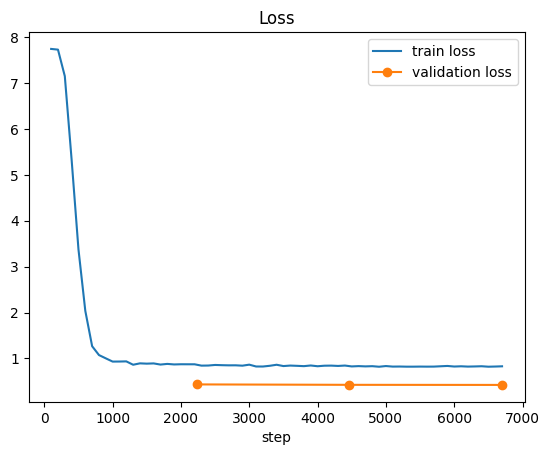

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from google.colab import files

log = pd.DataFrame(trainer.state.log_history); log.to_csv("training_log.csv", index=False)
ev = log[log["eval_loss"].notna()][["epoch", "eval_loss", "eval_accuracy", "eval_macro_f1"]]; print(ev.to_string(index=False))

tl = log[log["loss"].notna()]
plt.plot(tl["step"], tl["loss"], label="train loss"); plt.plot(ev["epoch"] * (tl["step"].max() / ev["epoch"].max()), ev["eval_loss"], "o-", label="validation loss")
plt.xlabel("step"); plt.legend(); plt.title("Loss"); plt.savefig("loss_curve.png", dpi=120); plt.show()

pd.DataFrame(rep).T.round(3).to_csv("per_class_report.csv")                       # rep: per-class table from the evaluation cell
pd.DataFrame(confusion_matrix(y, p), index=labels, columns=labels).to_csv("confusion_matrix.csv")
for f in ("training_log.csv", "per_class_report.csv", "confusion_matrix.csv", "loss_curve.png"): files.download(f)

In [ ]:
# ===== Paste this whole file into ONE new Colab cell (after training) and run it =====
# Needs the variables from the training notebook: trainer, tok, labels, i2l, te, va, ds_te, ds_va, THRESHOLD, MAX_LEN, MODEL_NAME
import os, json, shutil, datetime, numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from google.colab import files

COPY_MODEL_TO_DRIVE = True    # True: model goes to Google Drive (reliable for a big file). False: download the model zip in the browser.
EXPORT = "/content/crime_export"; RES = f"{EXPORT}/results"
shutil.rmtree(EXPORT, ignore_errors=True); os.makedirs(RES)
n = len(labels)

# 1) model + tokenizer + label list ------------------------------------------------
trainer.save_model(f"{EXPORT}/crime_model"); tok.save_pretrained(f"{EXPORT}/crime_model")
json.dump(labels, open(f"{EXPORT}/crime_model/labels.json", "w"))

# 2) training log + curves ----------------------------------------------------------
log = pd.DataFrame(trainer.state.log_history); log.to_csv(f"{RES}/training_log.csv", index=False)
ev = log[log["eval_loss"].notna()] if "eval_loss" in log else pd.DataFrame()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
if "loss" in log: tl = log[log["loss"].notna()]; ax[0].plot(tl["step"], tl["loss"]); ax[0].set_title("Training loss"); ax[0].set_xlabel("step")
if len(ev):
    ax[1].plot(ev["epoch"], ev["eval_loss"], "o-", label="val loss")
    for k in ("eval_accuracy", "eval_macro_f1"):
        if k in ev: ax[1].plot(ev["epoch"], ev[k], "o-", label=k.replace("eval_", "val "))
    ax[1].legend(); ax[1].set_title("Validation"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(f"{RES}/training_curves.png", dpi=130); plt.close()

# 3) test-set predictions and metrics ------------------------------------------------
def softmax(z): z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
out = trainer.predict(ds_te); pr = softmax(out.predictions); y = out.label_ids; p = pr.argmax(1); conf = pr.max(1)
pd.DataFrame({"text": te.text.values, "true": [i2l[i] for i in y], "pred": [i2l[i] for i in p],
              "confidence": conf.round(4), "correct": (y == p)}).to_csv(f"{RES}/test_predictions.csv", index=False)
rep = classification_report(y, p, labels=list(range(n)), target_names=labels, zero_division=0, output_dict=True)
pd.DataFrame(rep).T.round(4).to_csv(f"{RES}/per_class_report.csv")
pd.DataFrame(confusion_matrix(y, p, labels=list(range(n))), index=labels, columns=labels).to_csv(f"{RES}/confusion_matrix.csv")

# 4) confidence-threshold table (validation set) --------------------------------------
vp = trainer.predict(ds_va); pv = softmax(vp.predictions); cv = pv.max(1); okv = pv.argmax(1) == vp.label_ids
pd.DataFrame([{"threshold": t, "coverage": round(float((cv >= t).mean()), 4),
               "accuracy_on_answered": round(float(okv[cv >= t].mean()), 4) if (cv >= t).any() else None}
              for t in (0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)]).to_csv(f"{RES}/threshold_table.csv", index=False)

# 5) summary ------------------------------------------------------------------------------
summary = {"date": datetime.datetime.now().isoformat(timespec="seconds"), "base_model": MODEL_NAME, "num_labels": n,
           "max_len": MAX_LEN, "threshold": THRESHOLD, "test_rows": int(len(y)),
           "test_accuracy": round(float(accuracy_score(y, p)), 4), "test_macro_f1": round(float(f1_score(y, p, average="macro")), 4),
           "test_weighted_f1": round(float(f1_score(y, p, average="weighted")), 4),
           "last_val": ev.iloc[-1].dropna().to_dict() if len(ev) else {}}
json.dump(summary, open(f"{RES}/summary.json", "w"), indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))
print("\nWeakest 10 categories (F1):"); print(pd.DataFrame(rep).T.loc[labels].sort_values("f1-score").head(10)[["precision", "recall", "f1-score", "support"]].round(2).to_string())

# 6) standalone inference script for later use ---------------------------------------------
INFER = '''"""Use the saved model anywhere (laptop/server).
   pip install torch transformers sentencepiece pandas
   python crime_inference.py "Someone hacked my account" "My bike was stolen"
   python crime_inference.py --csv input.csv --col text      (writes input_predicted.csv)"""
import sys, json, argparse, torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
ap = argparse.ArgumentParser(); ap.add_argument("texts", nargs="*"); ap.add_argument("--model", default="crime_model")
ap.add_argument("--threshold", type=float, default=%s); ap.add_argument("--csv"); ap.add_argument("--col", default="text"); a = ap.parse_args()
tok = AutoTokenizer.from_pretrained(a.model); model = AutoModelForSequenceClassification.from_pretrained(a.model).eval()
labels = json.load(open(a.model + "/labels.json"))
def classify(texts):
    out = []
    for i in range(0, len(texts), 32):
        enc = tok(texts[i:i+32], truncation=True, max_length=%d, padding=True, return_tensors="pt")
        with torch.no_grad(): pr = torch.softmax(model(**enc).logits, dim=-1)
        for r in pr:
            top = r.argsort(descending=True)[:3].tolist()
            out.append((labels[top[0]] if r[top[0]] >= a.threshold else "uncertain", round(float(r[top[0]]), 3), [(labels[j], round(float(r[j]), 3)) for j in top]))
    return out
if a.csv:
    import pandas as pd
    d = pd.read_csv(a.csv); res = classify(d[a.col].astype(str).tolist())
    d["predicted"] = [r[0] for r in res]; d["confidence"] = [r[1] for r in res]; d["top3"] = [r[2] for r in res]
    d.to_csv(a.csv.replace(".csv", "_predicted.csv"), index=False); print("saved")
else:
    for t, r in zip(a.texts, classify(a.texts)): print(r[0], r[1], r[2], "<-", t[:60])
''' % (THRESHOLD, MAX_LEN)
open(f"{RES}/crime_inference.py", "w").write(INFER)

# 7) zip + download -----------------------------------------------------------------------------
shutil.make_archive("/content/crime_results", "zip", RES)                        # small: metrics, curves, predictions, inference script
files.download("/content/crime_results.zip")
if COPY_MODEL_TO_DRIVE:
    from google.colab import drive; drive.mount("/content/drive")
    shutil.copytree(f"{EXPORT}/crime_model", "/content/drive/MyDrive/crime_model", dirs_exist_ok=True)
    print("Model copied to Google Drive: MyDrive/crime_model")
else:
    shutil.make_archive("/content/crime_model", "zip", EXPORT, "crime_model"); files.download("/content/crime_model.zip")
print("Done.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
import json, shutil
from google.colab import files

trainer.save_model("crime_model"); tok.save_pretrained("crime_model")     # model + tokenizer
json.dump(labels, open("crime_model/labels.json", "w"))                   # category names
shutil.make_archive("crime_model", "zip", ".", "crime_model")             # creates crime_model.zip
files.download("crime_model.zip")                                         # sends it to your browser

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>